# Analyse et projection des recettes fiscales du Maroc (contexte PLF 2027)

**Objectif :** étudier l'évolution des recettes fiscales marocaines, leur lien avec le PIB, puis projeter les recettes de 2027 avec une régression linéaire simple.

**Plan du notebook**
1. Paramètres et chargement des données
2. Nettoyage et vérifications
3. Statistiques descriptives
4. Graphiques d'analyse
5. Modèle de régression linéaire et évaluation
6. Projection pour 2027 (3 scénarios)
7. Résumé des résultats
8. Limites

> **Données :** `donnees_recettes_fiscales.csv` (recettes fiscales du Ministère de l'Économie et des Finances, PIB nominal du HCP, en millions de dirhams). Sources et définitions détaillées dans le README ; les recettes 2024 et 2025 sont approximatives.

## 1. Paramètres et chargement des données

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# ----- PARAMETRES A ADAPTER -----
FICHIER = "donnees_recettes_fiscales.csv"
ANNEE_CIBLE = 2027                 # année à projeter
# Croissance du PIB NOMINAL (aux prix courants) retenue par le Ministère de l'Économie et des Finances
# dans le rapport d'exécution budgétaire du PLF 2027 : +6,8 % en 2026 et +6 % en 2027.
CROISSANCE_OFFICIELLE = {2026: 0.068, 2027: 0.060}
CROISSANCE_PAR_DEFAUT = 0.06       # utilisée pour une année non listée ci-dessus
ECART_SCENARIOS = 0.02             # scénario bas = officiel - 2 points ; haut = officiel + 2 points
NB_ANNEES_TEST = 2                 # nombre d'années récentes gardées pour tester le modèle
# Rappel : le PLF 2027 retient une croissance REELLE de 4,1 % en 2027 ; le PIB nominal (6 %) inclut en plus l'inflation.

In [2]:
df = pd.read_csv(FICHIER)
print("Aperçu des données :")
display(df.head())
print("\nTypes de colonnes :")
print(df.dtypes)
print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())

Aperçu des données :


,annee,recettes_fiscales_mdh,pib_mdh
0,2019,212638,1239836
1,2020,198793,1152419
2,2021,214565,1274700
3,2022,249382,1330500
4,2023,263249,1485600



Types de colonnes :
annee                    int64
recettes_fiscales_mdh    int64
pib_mdh                  int64
dtype: object

Valeurs manquantes par colonne :
annee                    0
recettes_fiscales_mdh    0
pib_mdh                  0
dtype: int64


## 2. Nettoyage et vérifications

On vérifie que les colonnes obligatoires existent, on convertit en nombres, on supprime les doublons et les années sans données.

In [3]:
colonnes_obligatoires = ["annee", "recettes_fiscales_mdh", "pib_mdh"]
manquantes = [c for c in colonnes_obligatoires if c not in df.columns]
assert not manquantes, f"Colonnes manquantes dans le fichier : {manquantes}"

# conversion numérique (les cellules illisibles deviennent NaN)
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

nb_avant = len(df)
df = (df.drop_duplicates(subset="annee")
        .sort_values("annee")
        .dropna(subset=colonnes_obligatoires)
        .reset_index(drop=True))
print(f"Lignes avant nettoyage : {nb_avant} | après : {len(df)}")
assert len(df) >= NB_ANNEES_TEST + 4, "Pas assez d'années renseignées pour entraîner et tester un modèle."

print(f"Période retenue : {int(df['annee'].min())} - {int(df['annee'].max())} ({len(df)} années)")

Lignes avant nettoyage : 7 | après : 7
Période retenue : 2019 - 2025 (7 années)


## 3. Statistiques descriptives

On calcule trois indicateurs :
- la **croissance annuelle** des recettes et du PIB ;
- la **pression fiscale** = recettes fiscales / PIB ;
- le **taux de croissance annuel moyen** (TCAM) des recettes sur la période.

In [4]:
df["croissance_recettes_pct"] = df["recettes_fiscales_mdh"].pct_change() * 100
df["croissance_pib_pct"] = df["pib_mdh"].pct_change() * 100
df["pression_fiscale_pct"] = df["recettes_fiscales_mdh"] / df["pib_mdh"] * 100

nb_periodes = df["annee"].iloc[-1] - df["annee"].iloc[0]
tcam_recettes = (df["recettes_fiscales_mdh"].iloc[-1] / df["recettes_fiscales_mdh"].iloc[0]) ** (1 / nb_periodes) - 1
tcam_pib = (df["pib_mdh"].iloc[-1] / df["pib_mdh"].iloc[0]) ** (1 / nb_periodes) - 1

print(f"TCAM des recettes fiscales : {tcam_recettes*100:.2f} % par an")
print(f"TCAM du PIB nominal        : {tcam_pib*100:.2f} % par an")
print(f"Pression fiscale moyenne   : {df['pression_fiscale_pct'].mean():.2f} % du PIB")
display(df.describe().round(2))

TCAM des recettes fiscales : 8.28 % par an
TCAM du PIB nominal        : 5.61 % par an
Pression fiscale moyenne   : 18.02 % du PIB


,annee,recettes_fiscales_mdh,pib_mdh,croissance_recettes_pct,croissance_pib_pct,pression_fiscale_pct
count,7.00,7.00,7.00,6.00,6.00,7.00
mean,2022.00,254346.71,1402546.43,8.57,5.80,18.02
std,2.16,52169.94,209495.22,8.46,6.83,1.10
min,2019.00,198793.00,1152419.00,-6.51,-7.05,16.83
25%,2020.50,213601.50,1257268.00,6.15,4.92,17.20
50%,2022.00,249382.00,1330500.00,10.76,7.61,17.72
75%,2023.50,281124.50,1550085.00,14.38,10.13,18.63
max,2025.00,342800.00,1720200.00,16.23,11.66,19.93


## 4. Graphiques d'analyse

Chaque graphique est enregistré dans le dossier `figures/`.

### Graphique 1 : évolution des recettes fiscales

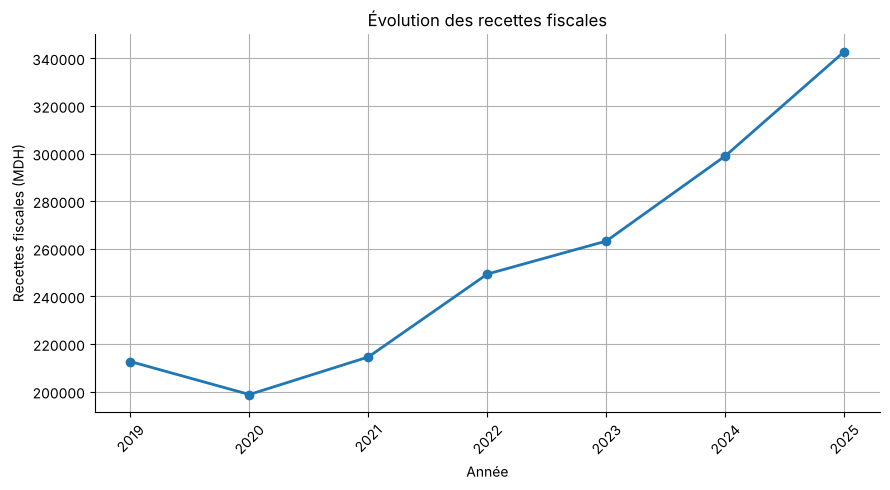

In [5]:
fig, ax = plt.subplots()
ax.plot(df["annee"], df["recettes_fiscales_mdh"], marker="o", linewidth=2)
ax.set_title("Évolution des recettes fiscales")
ax.set_xlabel("Année")
ax.set_ylabel("Recettes fiscales (MDH)")
ax.set_xticks(df["annee"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/01_evolution_recettes.png", dpi=150)
plt.show()

### Graphique 2 : croissance annuelle des recettes et du PIB

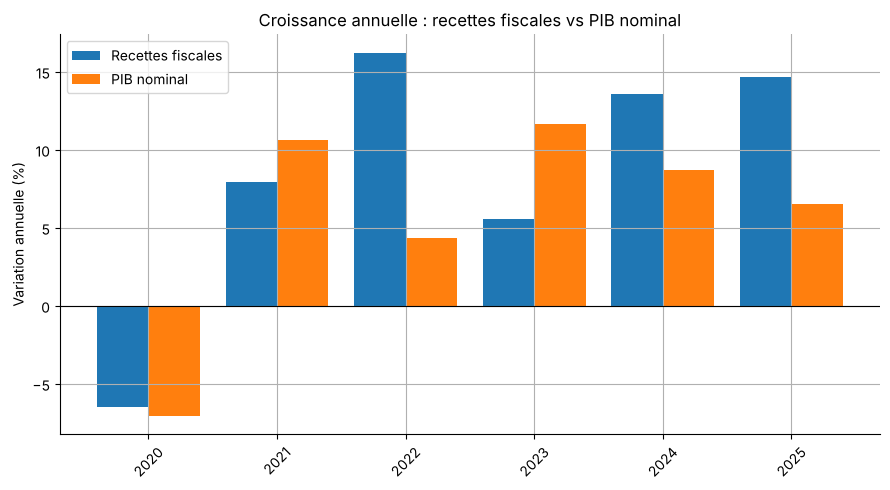

In [6]:
d = df.dropna(subset=["croissance_recettes_pct"])
x = np.arange(len(d))
largeur = 0.4
fig, ax = plt.subplots()
ax.bar(x - largeur/2, d["croissance_recettes_pct"], largeur, label="Recettes fiscales")
ax.bar(x + largeur/2, d["croissance_pib_pct"], largeur, label="PIB nominal")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(d["annee"].astype(int), rotation=45)
ax.set_title("Croissance annuelle : recettes fiscales vs PIB nominal")
ax.set_ylabel("Variation annuelle (%)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/02_croissance_annuelle.png", dpi=150)
plt.show()

### Graphique 3 : pression fiscale (recettes / PIB)

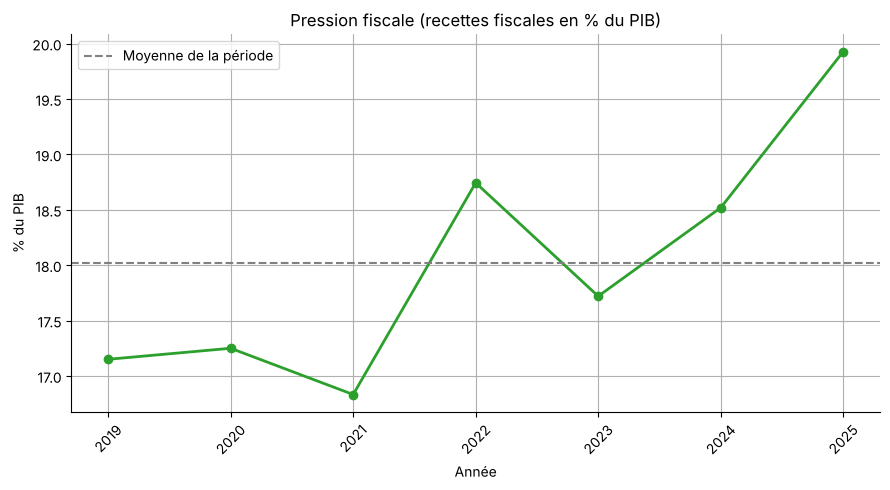

In [7]:
fig, ax = plt.subplots()
ax.plot(df["annee"], df["pression_fiscale_pct"], marker="o", linewidth=2, color="tab:green")
ax.axhline(df["pression_fiscale_pct"].mean(), linestyle="--", color="gray", label="Moyenne de la période")
ax.set_title("Pression fiscale (recettes fiscales en % du PIB)")
ax.set_xlabel("Année")
ax.set_ylabel("% du PIB")
ax.set_xticks(df["annee"])
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig("figures/03_pression_fiscale.png", dpi=150)
plt.show()

### Graphique 4 : composition des recettes (facultatif)
Ce graphique s'affiche seulement si les colonnes `is_mdh`, `ir_mdh` et `tva_mdh` sont renseignées dans le fichier de données.

In [8]:
cols_compo = ["is_mdh", "ir_mdh", "tva_mdh"]
if all(c in df.columns for c in cols_compo) and df[cols_compo].notna().all().all():
    fig, ax = plt.subplots()
    bas = np.zeros(len(df))
    noms = {"is_mdh": "Impôt sur les sociétés", "ir_mdh": "Impôt sur le revenu", "tva_mdh": "TVA"}
    for c in cols_compo:
        ax.bar(df["annee"], df[c], bottom=bas, label=noms[c])
        bas += df[c].values
    ax.set_title("Composition des principales recettes fiscales")
    ax.set_xlabel("Année")
    ax.set_ylabel("MDH")
    ax.legend()
    plt.tight_layout()
    plt.savefig("figures/04_composition.png", dpi=150)
    plt.show()
else:
    print("Colonnes IS / IR / TVA non renseignées : graphique ignoré.")

Colonnes IS / IR / TVA non renseignées : graphique ignoré.


## 5. Modèle de régression linéaire

Deux modèles simples sont comparés :
- **Modèle A** : recettes fiscales expliquées par le PIB nominal ;
- **Modèle B** : recettes fiscales expliquées par le temps (tendance).

**Évaluation :** comme les données sont des séries temporelles, on teste sur les **dernières années** (et non sur un échantillon au hasard) : le modèle apprend sur le passé et on vérifie s'il prédit bien les années les plus récentes.

### Graphique 5 : lien entre PIB et recettes fiscales

Corrélation recettes / PIB : 0.983


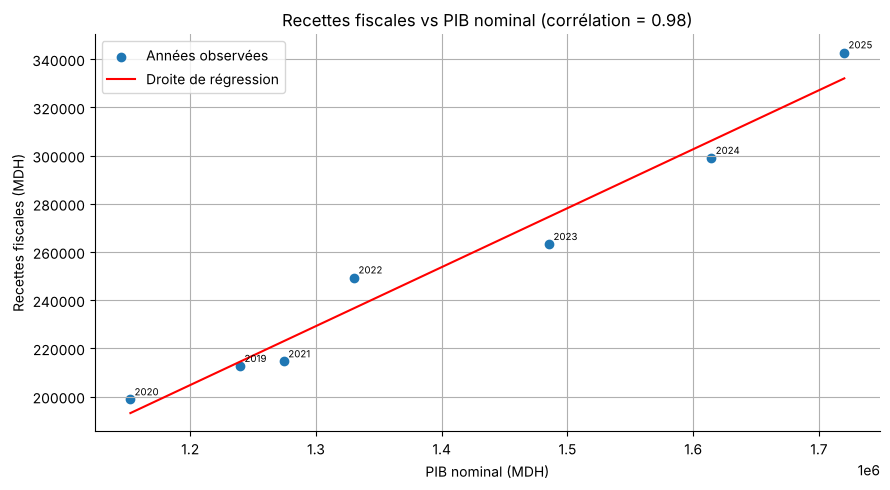

In [9]:
corr = df["recettes_fiscales_mdh"].corr(df["pib_mdh"])
print(f"Corrélation recettes / PIB : {corr:.3f}")

mA = LinearRegression().fit(df[["pib_mdh"]], df["recettes_fiscales_mdh"])
fig, ax = plt.subplots()
ax.scatter(df["pib_mdh"], df["recettes_fiscales_mdh"], label="Années observées")
xs = np.linspace(df["pib_mdh"].min(), df["pib_mdh"].max(), 100).reshape(-1, 1)
ax.plot(xs, mA.predict(pd.DataFrame(xs, columns=["pib_mdh"])), color="red", label="Droite de régression")
for _, r in df.iterrows():
    ax.annotate(int(r["annee"]), (r["pib_mdh"], r["recettes_fiscales_mdh"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title(f"Recettes fiscales vs PIB nominal (corrélation = {corr:.2f})")
ax.set_xlabel("PIB nominal (MDH)")
ax.set_ylabel("Recettes fiscales (MDH)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/05_recettes_vs_pib.png", dpi=150)
plt.show()

In [10]:
def evaluer(X, y, nom):
    """Entraîne sur les premières années, teste sur les NB_ANNEES_TEST dernières."""
    X_tr, X_te = X.iloc[:-NB_ANNEES_TEST], X.iloc[-NB_ANNEES_TEST:]
    y_tr, y_te = y.iloc[:-NB_ANNEES_TEST], y.iloc[-NB_ANNEES_TEST:]
    m = LinearRegression().fit(X_tr, y_tr)
    pred = m.predict(X_te)
    return {
        "modele": nom,
        "R2_entrainement": round(m.score(X_tr, y_tr), 3),
        "MAE_test_MDH": round(mean_absolute_error(y_te, pred), 1),
        "RMSE_test_MDH": round(float(np.sqrt(mean_squared_error(y_te, pred))), 1),
        "erreur_moyenne_test_pct": round(float(np.mean(np.abs((y_te - pred) / y_te)) * 100), 2),
    }

y = df["recettes_fiscales_mdh"]
evals = pd.DataFrame([
    evaluer(df[["pib_mdh"]], y, "A : recettes ~ PIB"),
    evaluer(df[["annee"]], y, "B : recettes ~ année"),
])
display(evals)
meilleur = evals.sort_values("RMSE_test_MDH").iloc[0]["modele"]
print("Modèle avec la plus faible erreur sur les années de test :", meilleur)

,modele,R2_entrainement,MAE_test_MDH,RMSE_test_MDH,erreur_moyenne_test_pct
0,A : recettes ~ PIB,0.894,16045.5,19405.1,4.79
1,B : recettes ~ année,0.776,40040.8,42520.8,12.23


Modèle avec la plus faible erreur sur les années de test : A : recettes ~ PIB


### Graphique 6 : résidus du modèle A (vérification)

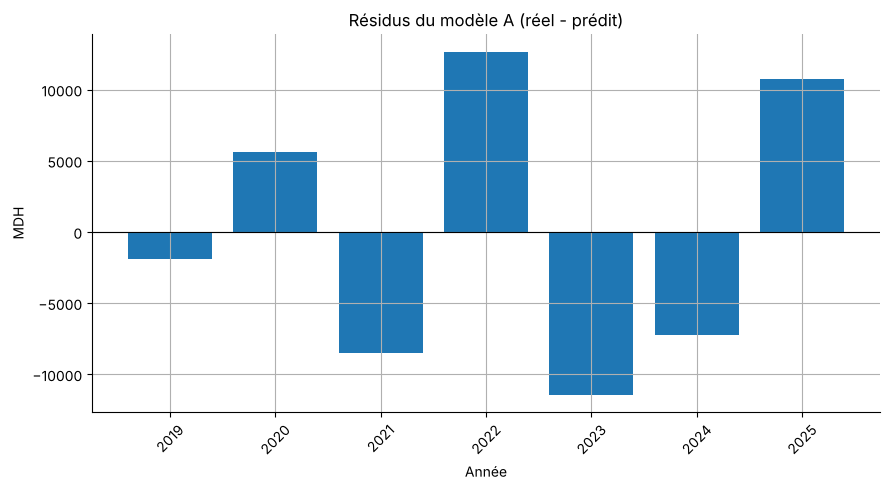

Si les résidus montrent un schéma net (toujours positifs puis négatifs), le modèle est trop simple.


In [11]:
residus = y - mA.predict(df[["pib_mdh"]])
fig, ax = plt.subplots()
ax.bar(df["annee"], residus)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Résidus du modèle A (réel - prédit)")
ax.set_xlabel("Année")
ax.set_ylabel("MDH")
ax.set_xticks(df["annee"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/06_residus.png", dpi=150)
plt.show()
print("Si les résidus montrent un schéma net (toujours positifs puis négatifs), le modèle est trop simple.")

## 6. Projection pour l'année cible

**Méthode :**
- Modèle A : on projette d'abord le PIB nominal avec trois scénarios (officiel -2 points, officiel, officiel +2 points), puis on en déduit les recettes.
- Modèle B : on prolonge simplement la tendance dans le temps.

> Le scénario central reprend la croissance nominale du PIB du rapport du Ministère pour le PLF 2027 (6,8 % en 2026, 6 % en 2027). Les scénarios bas et haut sont des **hypothèses** et non des prévisions officielles. 

In [12]:
derniere_annee = int(df["annee"].iloc[-1])
dernier_pib = df["pib_mdh"].iloc[-1]
annees_proj = list(range(derniere_annee + 1, ANNEE_CIBLE + 1))

def trajectoire_pib(ecart):
    # PIB projeté année par année : croissance officielle + un écart (scénario)
    pib, valeurs = dernier_pib, []
    for a in annees_proj:
        pib = pib * (1 + CROISSANCE_OFFICIELLE.get(a, CROISSANCE_PAR_DEFAUT) + ecart)
        valeurs.append(pib)
    return valeurs

scenarios = {"bas": -ECART_SCENARIOS, "central": 0.0, "haut": ECART_SCENARIOS}

proj = {}
lignes = []
for nom, ecart in scenarios.items():
    pib_proj = trajectoire_pib(ecart)
    rec_proj = mA.predict(pd.DataFrame({"pib_mdh": pib_proj}))
    proj[nom] = (pib_proj, rec_proj)
    lignes.append({
        "scenario": nom,
        "ecart_vs_officiel_points": round(ecart * 100, 1),
        f"PIB_{ANNEE_CIBLE}_MDH": round(pib_proj[-1]),
        f"recettes_{ANNEE_CIBLE}_MDH": round(rec_proj[-1]),
        "pression_fiscale_pct": round(rec_proj[-1] / pib_proj[-1] * 100, 2),
    })

mB = LinearRegression().fit(df[["annee"]], y)
rec_B = mB.predict(pd.DataFrame({"annee": annees_proj}))

resultats = pd.DataFrame(lignes)
display(resultats)
print(f"Modèle B (tendance) : recettes {ANNEE_CIBLE} = {rec_B[-1]:,.0f} MDH")

,scenario,ecart_vs_officiel_points,PIB_2027_MDH,recettes_2027_MDH,pression_fiscale_pct
0,bas,-2.0,1874880,369915,19.73
1,central,0.0,1947404,387659,19.91
2,haut,2.0,2021304,405741,20.07


Modèle B (tendance) : recettes 2027 = 368,558 MDH


### Graphique 7 : historique et projection

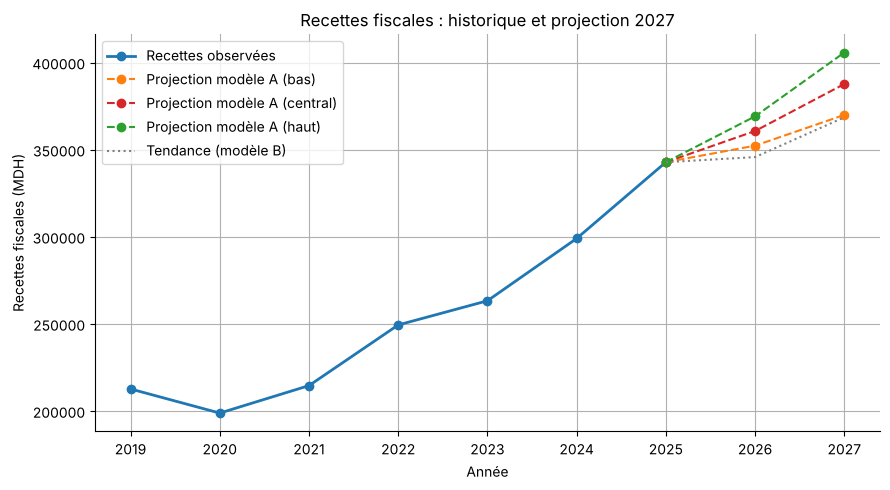

In [13]:
fig, ax = plt.subplots()
ax.plot(df["annee"], y, marker="o", linewidth=2, label="Recettes observées")
couleurs = {"bas": "tab:orange", "central": "tab:red", "haut": "tab:green"}
for nom, (_, rec) in proj.items():
    ax.plot([derniere_annee] + annees_proj, [y.iloc[-1]] + list(rec), linestyle="--", marker="o",
            color=couleurs[nom], label=f"Projection modèle A ({nom})")
ax.plot([derniere_annee] + annees_proj, [y.iloc[-1]] + list(rec_B), linestyle=":", color="gray", label="Tendance (modèle B)")
ax.set_title(f"Recettes fiscales : historique et projection {ANNEE_CIBLE}")
ax.set_xlabel("Année")
ax.set_ylabel("Recettes fiscales (MDH)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/07_projection.png", dpi=150)
plt.show()

## 7. Résumé des résultats

Les chiffres ci-dessous sont calculés par le code du notebook.

In [14]:
central = resultats[resultats["scenario"] == "central"].iloc[0]
print("=" * 60)
print("RESUME DES RESULTATS")
print("=" * 60)
print(f"Nombre d'années analysées : {len(df)}  ({int(df['annee'].min())}-{int(df['annee'].max())})")
print(f"Croissance moyenne annuelle des recettes (TCAM) : {tcam_recettes*100:.1f} %")
print(f"Corrélation recettes / PIB : {corr:.2f}")
print(f"R2 du modèle A (entraînement) : {evals.iloc[0]['R2_entrainement']}")
print(f"Erreur moyenne sur les années de test : {evals.iloc[0]['erreur_moyenne_test_pct']} %")
print(f"Recettes projetées {ANNEE_CIBLE} (scénario central) : {central[f'recettes_{ANNEE_CIBLE}_MDH']:,.0f} MDH")
print("=" * 60)

resultats.to_csv("resultats_projection.csv", index=False)
evals.to_csv("evaluation_modeles.csv", index=False)

RESUME DES RESULTATS
Nombre d'années analysées : 7  (2019-2025)
Croissance moyenne annuelle des recettes (TCAM) : 8.3 %
Corrélation recettes / PIB : 0.98
R2 du modèle A (entraînement) : 0.894
Erreur moyenne sur les années de test : 4.79 %
Recettes projetées 2027 (scénario central) : 387,659 MDH


## 8. Limites

- **Très peu d'observations** (une valeur par an) : la projection est fragile et le R² peut être trompeur.
- **Corrélation n'est pas causalité** : le lien entre PIB et recettes n'est pas démontré comme causal ici.
- **Deux variables en tendance** : recettes et PIB nominal augmentent presque toujours ensemble, ce qui gonfle la corrélation (régression dite « fallacieuse »).
- **Pas de réformes ni de chocs** : le modèle ignore les changements de taux, les réformes fiscales et les chocs (sécheresse, crise, etc.).
- **Hypothèse de PIB** : le résultat dépend de l'hypothèse de croissance retenue, d'où les trois scénarios.
- **Projection ≠ prévision officielle** : ce travail est un exercice d'initiation et ne remplace pas les prévisions du Ministère des Finances.

**Pistes d'amélioration :** ajouter l'inflation, passer à des données trimestrielles ou mensuelles, tester une série temporelle (ARIMA), comparer avec le déficit budgétaire.